# Qwen-Image-2.1 trên Google Colab: tải model từ Hugging Face và tạo ảnh

- Model: [`Qwen/Qwen-Image-2.1`](https://huggingface.co/Qwen/Qwen-Image-2.1), DiT 7B + text encoder Qwen3-VL, chạy qua `QwenImage21Pipeline` của 🤗 Diffusers.
- Runtime: **Runtime → Change runtime type → GPU**. Checkpoint lớn (cell 4 sẽ in dung lượng thực tế), nên cần GPU nhiều VRAM (A100 là tốt nhất, L4 24GB chạy được bằng CPU offload). GPU nhỏ như T4 có thể không đủ.
- License: Qwen Research License (chỉ dùng phi thương mại).
- Chạy lần lượt từng cell từ trên xuống.

In [ ]:
# 1) Check the runtime: GPU, VRAM, system RAM, free disk
import shutil
import subprocess

import psutil
import torch

print(subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"],
    capture_output=True, text=True).stdout or "No NVIDIA GPU found")
assert torch.cuda.is_available(), "No GPU. Use Runtime > Change runtime type and select a GPU."

vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
ram_gb = psutil.virtual_memory().total / 1024**3
disk_free_gb = shutil.disk_usage("/content").free / 1024**3
print(f"torch {torch.__version__} | VRAM {vram_gb:.1f} GB | RAM {ram_gb:.1f} GB | free disk {disk_free_gb:.1f} GB")

major, _ = torch.cuda.get_device_capability(0)
if major < 8:
    print("WARNING: this GPU has no native bfloat16 (e.g. T4). Expect very slow or failing inference.")

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07

torch 2.14.1+cu130 | VRAM 14.6 GB | RAM 12.7 GB | free disk 81.2 GB


In [ ]:
# 2) Install dependencies (versions follow the official model card)
# Diffusers comes from GitHub main because QwenImage21Pipeline is new.
# bitsandbytes (4-bit loading for small GPUs, see cell 5) must be installed BEFORE diffusers is first imported.
!pip install -q -U "transformers>=5.17" accelerate pillow "huggingface_hub[hf_xet]" bitsandbytes git+https://github.com/huggingface/diffusers


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 3) Optional: Hugging Face token (higher rate limits; needed only if the repo asks you to accept its terms)
# Add a secret named HF_TOKEN in Colab (left sidebar > key icon) and enable notebook access.
import os

try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("HF_TOKEN loaded from Colab secrets.")
except Exception as e:
    print("No HF_TOKEN secret available, continuing anonymously:", type(e).__name__)

No HF_TOKEN secret available, continuing anonymously: SecretNotFoundError


In [ ]:
# 4) Download the model from the Hugging Face Hub to local disk
import shutil

from huggingface_hub import HfApi, snapshot_download

REPO_ID = "Qwen/Qwen-Image-2.1"
LOCAL_DIR = "/content/models/Qwen-Image-2.1"

info = HfApi().model_info(REPO_ID, files_metadata=True)
total_gb = sum((s.size or 0) for s in info.siblings) / 1024**3
free_gb = shutil.disk_usage("/content").free / 1024**3
print(f"{REPO_ID}: {len(info.siblings)} files, {total_gb:.1f} GB (free disk: {free_gb:.1f} GB)")
assert total_gb < free_gb, "Not enough free disk space for this model."

model_path = snapshot_download(repo_id=REPO_ID, local_dir=LOCAL_DIR)
print("Downloaded to:", model_path)

Qwen/Qwen-Image-2.1: 28 files, 30.9 GB (free disk: 81.2 GB)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 28 files:   0%|          | 0/28 [00:00<?, ?it/s]

Downloaded to: /content/models/Qwen-Image-2.1


In [ ]:
# 5) Load the pipeline; choose placement/quantization by available VRAM (40 GB is a rough heuristic)
import gc

import torch
from diffusers import QwenImage21Pipeline

if vram_gb >= 40:
    # Large GPU (e.g. A100 80GB): full bf16 pipeline on the GPU, fastest.
    pipe = QwenImage21Pipeline.from_pretrained(model_path, dtype=torch.bfloat16)
    pipe.to("cuda")
    print("Mode: full GPU, bf16")
else:
    # Small GPU / small RAM (e.g. free-tier T4: 15 GB VRAM, 12.7 GB RAM): the ~31 GB bf16 checkpoint
    # cannot be loaded as-is, so quantize the two big components (7B DiT + Qwen3-VL text encoder)
    # to 4-bit NF4 while loading (about 11 GB in total).
    from diffusers import PipelineQuantizationConfig

    quant_config = PipelineQuantizationConfig(
        quant_backend="bitsandbytes_4bit",
        quant_kwargs={
            "load_in_4bit": True,
            "bnb_4bit_quant_type": "nf4",
            "bnb_4bit_compute_dtype": torch.bfloat16,
        },
        components_to_quantize=["transformer", "text_encoder"],
    )
    pipe = QwenImage21Pipeline.from_pretrained(
        model_path, dtype=torch.bfloat16, quantization_config=quant_config
    )
    # Do NOT call enable_model_cpu_offload() here: it copies the weights into the 12.7 GB of system RAM
    # and crashes the session. The quantized parts are already on the GPU; move the rest (VAE) there too.
    pipe.vae.to("cuda")
    try:
        pipe.vae.enable_tiling()  # lower peak VRAM when decoding the image
    except Exception as e:
        print("VAE tiling not available:", type(e).__name__)
    print("Mode: 4-bit NF4, everything on GPU")

gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1024**3:.1f} GB of {vram_gb:.1f} GB")


Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Mode: 4-bit NF4, everything on GPU
GPU memory in use: 10.7 GB of 14.6 GB


  0%|          | 0/40 [00:00<?, ?it/s]

Saved /content/outputs/qwen_image_2_1.png (768x768)


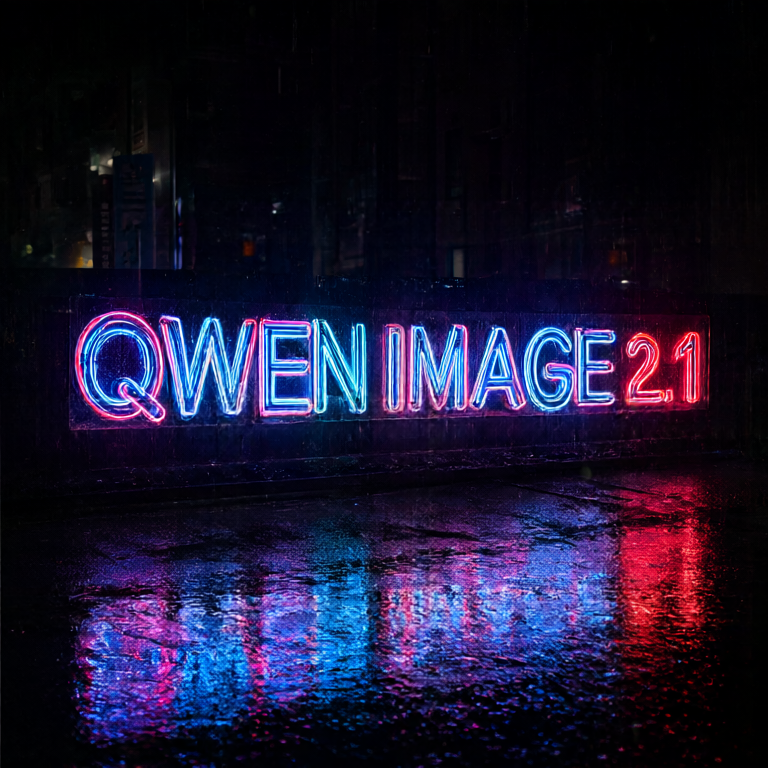

In [ ]:
# 6) Text-to-image inference
import os

import torch
from IPython.display import display

SIZES = {  # resolutions recommended by the model card: (width, height)
    "1:1": (2048, 2048), "4:3": (2400, 1792), "3:4": (1792, 2400),
    "3:2": (2528, 1696), "2:3": (1696, 2528), "16:9": (2752, 1536), "9:16": (1536, 2752),
}
SIZES_SMALL = {  # about 0.6 megapixel, same aspect ratios, all multiples of 32
    "1:1": (768, 768), "4:3": (896, 672), "3:4": (672, 896),
    "3:2": (960, 640), "2:3": (640, 960), "16:9": (1024, 576), "9:16": (576, 1024),
}
# On a small GPU (e.g. T4) the 4-bit model already takes ~11 GB, and PyTorch's bf16 attention on T4 needs
# a lot of extra memory, so 2K (and even 1024x1024) run out of memory and are far too slow. Use small sizes.
if vram_gb < 40:
    SIZES = SIZES_SMALL


def generate(prompt, aspect="1:1", steps=40, seed=42, out_path="/content/outputs/qwen_image_2_1.png"):
    width, height = SIZES[aspect]
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    image = pipe(
        prompt=prompt,
        width=width,
        height=height,
        num_inference_steps=steps,
        generator=torch.Generator("cuda").manual_seed(seed),
    ).images[0]
    image.save(out_path)
    print(f"Saved {out_path} ({image.size[0]}x{image.size[1]})")
    return image


prompt = ('A neon shop sign that reads "QWEN IMAGE 2.1", rainy night, '
          'reflections on wet pavement')
image = generate(prompt, aspect="1:1", steps=40, seed=42)

preview = image.copy()
preview.thumbnail((1024, 1024))
display(preview)


  0%|          | 0/40 [00:00<?, ?it/s]

Saved /content/outputs/qwen_image_2_1_uc1.png (768x768)


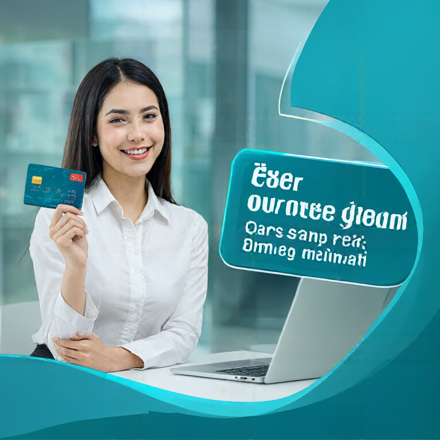

In [11]:
# 6) Text-to-image inference
import os

import torch
from IPython.display import display

SIZES = {  # resolutions recommended by the model card: (width, height)
    "1:1": (2048, 2048), "4:3": (2400, 1792), "3:4": (1792, 2400),
    "3:2": (2528, 1696), "2:3": (1696, 2528), "16:9": (2752, 1536), "9:16": (1536, 2752),
}
SIZES_SMALL = {  # about 0.6 megapixel, same aspect ratios, all multiples of 32
    "1:1": (768, 768), "4:3": (896, 672), "3:4": (672, 896),
    "3:2": (960, 640), "2:3": (640, 960), "16:9": (1024, 576), "9:16": (576, 1024),
}
# On a small GPU (e.g. T4) the 4-bit model already takes ~11 GB, and PyTorch's bf16 attention on T4 needs
# a lot of extra memory, so 2K (and even 1024x1024) run out of memory and are far too slow. Use small sizes.
if vram_gb < 40:
    SIZES = SIZES_SMALL


def generate(prompt, aspect="1:1", steps=40, seed=42, out_path="/content/outputs/qwen_image_2_1_uc1.png"):
    width, height = SIZES[aspect]
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    image = pipe(
        prompt=prompt,
        width=width,
        height=height,
        num_inference_steps=steps,
        generator=torch.Generator("cuda").manual_seed(seed),
    ).images[0]
    image.save(out_path)
    print(f"Saved {out_path} ({image.size[0]}x{image.size[1]})")
    return image


prompt = ('Thiêt kế banner quảng cáo cho bank với logo OCB, tông màu xanh chiếm 40% diện tích nằm bên phải, bên trái là hình background nhân vật nữ 24 tuổi, ngồi trên bàn làm việc ở văn phòng, trên bàn có laptop, phía sau là văn phòng hiện đại. Từ bên phải sang bên trái chuyển màu TRANSPARENT GRADIENT '
          'Nhân vật cầm card, mặt nhìn về phía người xem, vui vẻ đưa card ra giới thiệu')
image = generate(prompt, aspect="1:1", steps=40, seed=42)


preview = image.copy()
preview.thumbnail((1024, 440))
display(preview)


In [ ]:
# 7) Optional: download the result to your computer and free GPU memory.
# Uncomment the lines you need.
# from google.colab import files
# files.download("/content/outputs/qwen_image_2_1.png")

# del pipe
# gc.collect()
# torch.cuda.empty_cache()


pixels min/max/mean: 0.0 255.0 11.831


  0%|          | 0/2 [00:00<?, ?it/s]

Tensor (1, 2304, 64) torch.bfloat16
nan: False | inf: False | absmax: 5.53125 | mean: -0.014388945885002613
